In [1]:
%pip install mrcfile

   ---------------------------------------- 0.0/45.0 kB ? eta -:--:--
   ------------------------------------ --- 41.0/45.0 kB ? eta -:--:--
   ------------------------------------ --- 41.0/45.0 kB ? eta -:--:--
   ---------------------------------------- 45.0/45.0 kB 319.0 kB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
np.array(test)

array([[0.2786536 , 0.47826955, 0.5250156 , ..., 0.641018  , 0.657412  ,
        0.70366794],
       [0.6738792 , 0.6378798 , 0.6698502 , ..., 0.60422707, 0.60007256,
        0.68329626],
       [0.66591376, 0.67126054, 0.6814868 , ..., 0.5941566 , 0.5961555 ,
        0.59439826],
       ...,
       [0.6370504 , 0.6197925 , 0.6179022 , ..., 0.6040435 , 0.5802154 ,
        0.57381696],
       [0.6508552 , 0.71445245, 0.6414263 , ..., 0.6452339 , 0.6502237 ,
        0.6229989 ],
       [0.64156026, 0.60187113, 0.531995  , ..., 0.6911548 , 0.67331845,
        0.57890606]], shape=(1024, 1024), dtype=float32)

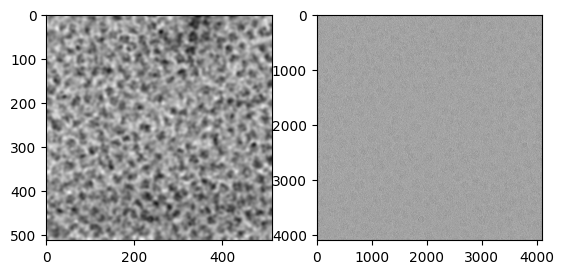

In [ ]:
import mrcfile 
import matplotlib.pyplot as plt 
import cv2
import numpy as np

with mrcfile.open("image3.mrc") as mrc:
    data = mrc.data
    
test = (data-np.min(data))
test = test/np.max(test)


# re_test  = test.resize((int(test.shape[0]/4),int(test.shape[1]/4)))
re_test  = cv2.resize(test, (int(test.shape[0]/8),int(test.shape[1]/8)))
test_gauss = cv2.GaussianBlur(re_test, (21,21), 0) # (5x5) es el tamaño del filtro y 0 es la desviación estándar




plt.subplot(1,2,1)
plt.imshow(test_gauss, cmap= "gray")
plt.subplot(1,2,2)
plt.imshow(test, cmap="gray")
plt.show()

0.65624285
0.6120979
0.63686395


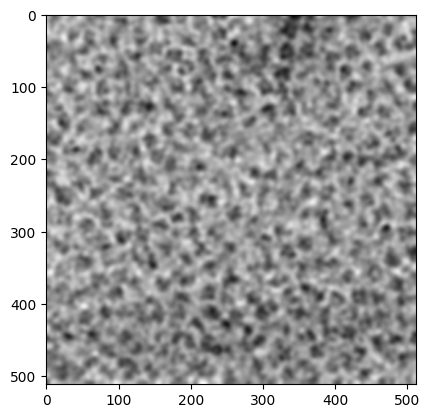

In [ ]:
# mask2 = test < 0.37    
# 
# test2 = test*mask2

test_gauss_d = (test_gauss-np.min(test_gauss))
test_gauss_d = test/np.max(test_gauss_d)

print(test_gauss.max())
print(test_gauss.min())
print(test_gauss.mean())

mask1 = test_gauss > 0
test1 = test_gauss*mask1

plt.imshow(test1, cmap="gray")

In [75]:
test_gauss.shape

(512, 512)

Media de la imagen: 0.6368963122367859


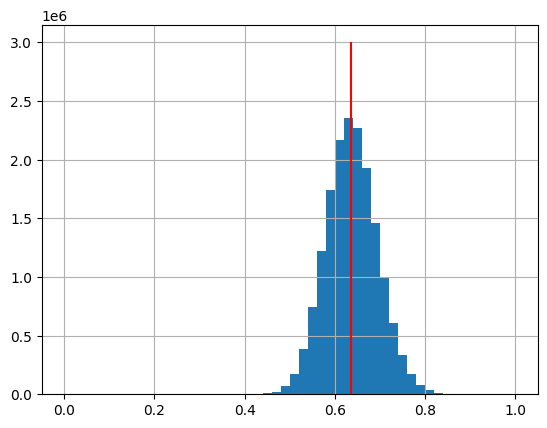

In [ ]:
# Calculamos el histograma
import cv2

hist = cv2.calcHist([test_gauss], [0], None, [256], [0, 256])     # [0] son los canales, None la máscara

media_directa = np.mean(test)
print(f"Media de la imagen: {media_directa}")


# Otra forma de mostrar el histograma (solo visualización)

plt.hist(test.ravel(), bins=50)
plt.vlines(media_directa, ymin=0, ymax=3e6, color = "red")
plt.grid(True)
plt.show()


In [11]:
import pandas as pd 

data_img_clustering = []
for i in range(test1.shape[0]):
    for j in range(test1.shape[0]):
        if test1[i,j] != 0:
            data_img_clustering.append((i,j))

# df = pd.DataFrame

In [12]:
data_img_clustering

[(0, 3),
 (0, 4),
 (0, 5),
 (0, 6),
 (0, 7),
 (0, 8),
 (0, 17),
 (0, 18),
 (0, 25),
 (0, 27),
 (0, 28),
 (0, 37),
 (0, 38),
 (0, 40),
 (0, 41),
 (0, 42),
 (0, 49),
 (0, 50),
 (0, 51),
 (0, 52),
 (0, 59),
 (0, 62),
 (0, 63),
 (0, 67),
 (0, 73),
 (0, 74),
 (0, 83),
 (0, 92),
 (0, 98),
 (0, 99),
 (0, 118),
 (0, 119),
 (0, 120),
 (0, 121),
 (0, 136),
 (0, 137),
 (0, 138),
 (0, 139),
 (0, 140),
 (0, 141),
 (0, 142),
 (0, 143),
 (0, 144),
 (0, 145),
 (0, 146),
 (0, 147),
 (0, 148),
 (0, 149),
 (0, 170),
 (0, 173),
 (0, 174),
 (0, 175),
 (0, 176),
 (0, 177),
 (0, 178),
 (0, 179),
 (0, 180),
 (0, 189),
 (0, 190),
 (0, 194),
 (0, 195),
 (0, 196),
 (0, 197),
 (0, 198),
 (0, 199),
 (0, 200),
 (0, 201),
 (0, 202),
 (0, 203),
 (0, 204),
 (0, 205),
 (0, 281),
 (0, 282),
 (0, 283),
 (0, 284),
 (0, 285),
 (0, 286),
 (0, 287),
 (0, 297),
 (0, 307),
 (0, 308),
 (0, 311),
 (0, 312),
 (0, 324),
 (0, 325),
 (0, 329),
 (0, 330),
 (0, 334),
 (0, 335),
 (0, 336),
 (0, 341),
 (0, 354),
 (0, 355),
 (0, 357),
 (

### Affinity Propagation / K-means

In [23]:
from sklearn.cluster import AffinityPropagation

X = data_img_clustering
X
# X_tests = X[:len(X)/4]

clustering = AffinityPropagation()

cosas = clustering.fit(X)

clustering.predict()

MemoryError: Unable to allocate 106. TiB for an array with shape (3825195, 3825195) and data type float64